# Post 1: data and pipeline check

Loads MNIST (or CIFAR-10), looks at a few batches, builds the skeleton model from
`model.py`, and pushes it through the shared training harness for a few steps.
Nothing here trains a useful model yet: the model is a placeholder linear layer
and the loss is a placeholder too. Their job is to show that data, model,
`Experiment`, checkpoints, logs and inference fit together, so that once you
fill in `CNN` and `loss_fn`, re-running this notebook is a real smoke test.

Switch `DATASET` to `"cifar10"` to run the same pipeline on CIFAR-10 (a 160 MB
download on first use).

## Setup

On Colab this clones the repo and installs it with the `posts` extra. Locally
(`uv run jupyter lab`, or VS Code with the repo's `.venv`) it does nothing.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !git clone --depth 1 https://github.com/anujkhare/toylib.git /content/toylib
    %cd /content/toylib
    !pip install -q -e ".[posts]"

In [2]:
import json
import pathlib
import shutil

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax
from absl import logging as absl_logging

from toylib import viz
from toylib.harness import analyze, inference
from toylib.harness.experiment import (
    CheckpointConfig,
    EvalConfig,
    Experiment,
    LoggerConfig,
    Task,
    TrainingConfig,
)
from toylib.harness.metrics import Loss
from toylib_projects.p01_cnn_mnist import data, metrics, model

DATASET = "mnist"  # or "cifar10"
BATCH_SIZE = 128

absl_logging.set_verbosity(absl_logging.ERROR)  # quiet orbax's read-only notices
viz.use_style()
info = data.DATASETS[DATASET]
print("JAX devices:", jax.devices())

JAX devices: [CpuDevice(id=0)]


## 1. Load the data

`make_datasets` downloads once (cached under `~/.cache/toylib`), scales pixels
to zero mean and unit variance per channel, and wraps the arrays in
`ArrayDataset`: shuffled fixed-size batches for training, a fixed order for test.

In [3]:
train_ds, test_ds = data.make_datasets(DATASET, batch_size=BATCH_SIZE, eval_batch_size=500)

for split, ds in [("train", train_ds), ("test", test_ds)]:
    x, y = ds.arrays["image"], ds.arrays["label"]
    print(f"{split:5s} image {x.shape} {x.dtype}  label {y.shape} {y.dtype}  "
          f"{ds.batches_per_epoch} batches of {ds.batch_size}")
print("train label counts:", np.bincount(train_ds.arrays["label"]))
print(f"train pixel mean {train_ds.arrays['image'].mean():.3f}, std {train_ds.arrays['image'].std():.3f}")

train image (60000, 28, 28, 1) float32  label (60000,) int32  468 batches of 128
test  image (10000, 28, 28, 1) float32  label (10000,) int32  20 batches of 500
train label counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
train pixel mean -0.000, std 1.000


## 2. A few batches

Iterating a dataset yields dicts of NumPy arrays. Pixel statistics per batch
should hover around mean 0 and std 1.

batch 0: image (128, 28, 28, 1) float32, label (128,) int32  | mean -0.003 std 0.997
batch 1: image (128, 28, 28, 1) float32, label (128,) int32  | mean +0.021 std 1.022
batch 2: image (128, 28, 28, 1) float32, label (128,) int32  | mean -0.005 std 0.997


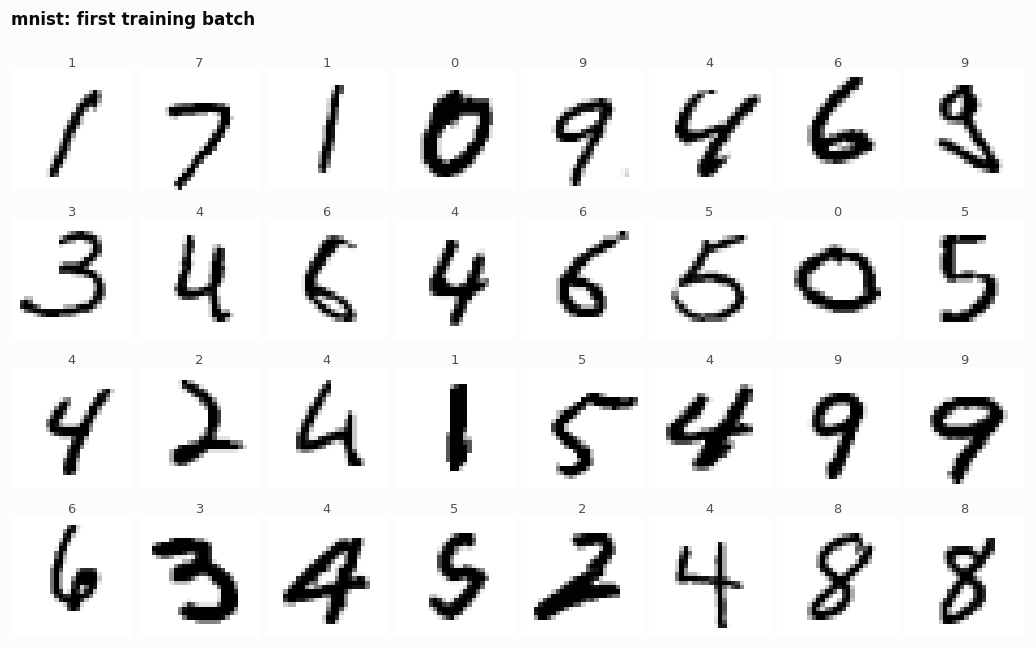

In [4]:
batches = []
for i, batch in zip(range(3), train_ds):
    batches.append(batch)
    print(f"batch {i}: " + ", ".join(f"{k} {v.shape} {v.dtype}" for k, v in batch.items())
          + f"  | mean {batch['image'].mean():+.3f} std {batch['image'].std():.3f}")

batch = batches[0]
fig = viz.image_grid(
    data.unpreprocess(batch["image"][:32], info),
    titles=[info.class_names[int(c)] for c in batch["label"][:32]],
    suptitle=f"{DATASET}: first training batch",
)

## 3. The model skeleton

`build_model` is the harness's `model_factory`. The shape trace below comes from
`return_intermediates=True`; once you add conv and pooling layers, compare it
with your hand calculation.

In [5]:
config = model.ModelConfig(image_shape=info.image_shape, num_classes=len(info.class_names))
net = model.build_model(config, jax.random.key(0))

logits, acts = net(batch["image"], return_intermediates=True)
print("input  ", batch["image"].shape)
for name, a in acts.items():
    print(f"{name:7s}", a.shape)
print("logits ", logits.shape)

table, n_params, n_bytes = analyze.print_param_sizes(net, depth=1)
table

input   (128, 28, 28, 1)
flatten (128, 784)
logits  (128, 10)
Total Parameters: 7,850. Bytes: (31,400.00)


,level_0,dtype,params,n_bytes_divided
0,.head,float32,7850,31400.0


## 4. Dummy passes by hand

One loss and gradient evaluation, then a few jitted Adam steps on a single
batch. With the placeholder loss the value only says that gradients flow; with
cross-entropy, the loss on one repeated batch should fall fast.

In [6]:
loss, aux = model.forward(net, batch)
grads = jax.grad(lambda m: model.forward(m, batch)[0])(net)
print("loss", float(loss), "| accuracy", float(metrics.Accuracy()(loss, aux, batch)["accuracy"]))
print("grad norms:", {jax.tree_util.keystr(p): float(jnp.linalg.norm(g))
                      for p, g in jax.tree_util.tree_leaves_with_path(grads)})


optimizer = optax.adam(1e-3)


@jax.jit
def train_step(m, opt_state, b):
    loss, g = jax.value_and_grad(lambda m: model.forward(m, b)[0])(m)
    updates, opt_state = optimizer.update(g, opt_state, m)
    return optax.apply_updates(m, updates), opt_state, loss


m, opt_state = net, optimizer.init(net)
for step in range(10):
    m, opt_state, loss = train_step(m, opt_state, batch)
    print(f"step {step}: loss {float(loss):.4f}")

loss 0.009280127473175526 | accuracy 0.09375
grad norms: {'.head.weights': 0.44884273409843445, '.head.bias': 0.022947652265429497}
step 0: loss 0.0093
step 1: loss 0.0661
step 2: loss 0.0116
step 3: loss 0.0295
step 4: loss 0.0326
step 5: loss 0.0179
step 6: loss 0.0093
step 7: loss 0.0110
step 8: loss 0.0165
step 9: loss 0.0164


## 5. A few steps through `Experiment`

The same `model_factory` and `forward_fn`, now driven by the harness: jitted
train steps, evaluation on the test set, checkpoints and a JSON-lines log.
Outputs go to `toylib_projects/p01_cnn_mnist/outputs/` (gitignored), and the run
directory is wiped first so re-running starts clean.

In [7]:
out_dir = (pathlib.Path(model.__file__).parent / "outputs" / f"notebook_{DATASET}").resolve()
shutil.rmtree(out_dir, ignore_errors=True)

task_metrics = [Loss(), metrics.Accuracy()]
exp = Experiment(
    train_task=Task("train", train_ds, metrics=task_metrics),
    eval_task=Task("test", test_ds, metrics=task_metrics),
    model_factory=model.build_model,
    forward_fn=model.forward,
    model_config=config,
    training_config=TrainingConfig(max_steps=30),
    eval_config=EvalConfig(eval_interval_steps=10, num_eval_steps=2),
    checkpoint_config=CheckpointConfig(save_interval_steps=10, checkpoint_dir=str(out_dir / "checkpoints")),
    logger_config=LoggerConfig(log_dir=str(out_dir), run_id="smoke", train_log_interval_steps=5),
)
exp.init_state()
exp.outer_loop()
exp.cleanup()

Initialized mesh Mesh('data': 1, axis_types=(Auto,)) with 1 devices: [CpuDevice(id=0)]


Using default optimizer: Adam, lr=1e-3
Model initialized and replicated across 1 devices


{'train/accuracy': 0.1016, 'train/loss': 0.0085, 'step': 0}
{'val/accuracy': 0.116, 'val/loss': 0.0596, 'step': 0}
{'train/accuracy': 0.0234, 'train/loss': 0.0171, 'train/steps_per_sec': 34.7356, 'step': 5}
{'train/accuracy': 0.0781, 'train/loss': 0.0096, 'train/steps_per_sec': 69.0966, 'step': 10}
{'val/accuracy': 0.128, 'val/loss': 0.0066, 'step': 10}
{'train/accuracy': 0.125, 'train/loss': 0.0068, 'train/steps_per_sec': 91.4686, 'step': 15}
{'train/accuracy': 0.0469, 'train/loss': 0.0047, 'train/steps_per_sec': 121.4463, 'step': 20}
{'val/accuracy': 0.058, 'val/loss': 0.0034, 'step': 20}
{'train/accuracy': 0.1094, 'train/loss': 0.0038, 'train/steps_per_sec': 138.787, 'step': 25}


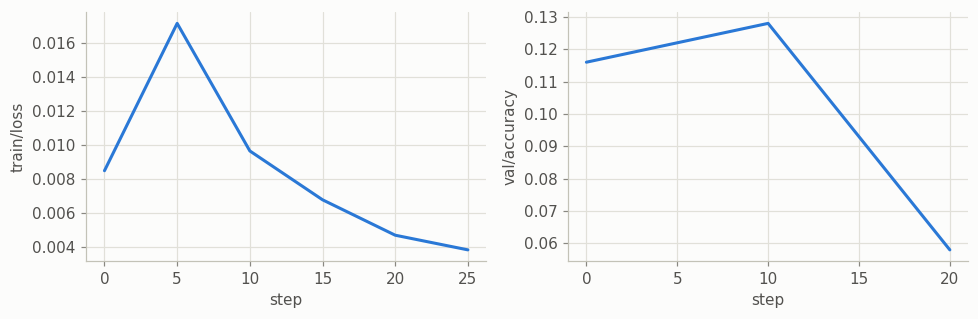

In [8]:
log_path = out_dir / "logs_smoke.txt"
for line in log_path.read_text().splitlines():
    if line.strip():
        record = json.loads(line)
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in record.items() if k != "timestamp"})

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
viz.plot_curves({"smoke": log_path}, "train/loss", ax=axes[0])
viz.plot_curves({"smoke": log_path}, "val/accuracy", ax=axes[1])
fig.tight_layout()

## 6. Load a checkpoint and run inference

What `figures.py` will do later: list the checkpoints, restore the latest into a
fresh model, and run it over the test set in batches.

In [9]:
steps = inference.checkpoint_steps(out_dir / "checkpoints")
print("checkpoints at steps", steps)

restored = inference.load_model(model.build_model(config, jax.random.key(1)), out_dir / "checkpoints")
test_logits = inference.batched_apply(lambda m, b: m(b["image"]), restored, {"image": test_ds.arrays["image"]}, 500)
test_acc = float(np.mean(test_logits.argmax(-1) == test_ds.arrays["label"]))
print(f"test logits {test_logits.shape}, accuracy {test_acc:.3f} (placeholder model and loss)")

checkpoints at steps [0, 10, 20]
test logits (10000, 10), accuracy 0.056 (placeholder model and loss)


## Next

1. Replace `loss_fn` in `model.py` with softmax cross-entropy and re-run
   section 4: the loss on the repeated batch should drop quickly.
2. Fill in `CNN`: conv, pooling, then a flatten or global-average-pool head.
   Check the shape trace in section 3.
3. Bump `max_steps` in section 5 and watch `val/accuracy` climb, then move the
   setup into `train.py` (milestone 4 in the README).